# <font color='blue'>FUMEC - Analytics com Python</font>
## **Trabalho Autoinstrucional**


Aluno: Gustavo Costa <br>
Disciplina: Analytics com Python

## Objetivo

Este trabalho tem como objetivo aplicar técnicas de Machine Learning utilizando o algoritmo Árvore de Decisão para classificar tumores mamários como benignos ou malignos.

A classificação correta desses tumores pode auxiliar no apoio ao diagnóstico médico, permitindo identificar padrões presentes nos dados coletados.

## Fonte dos Dados

Foi utilizado o conjunto de dados Breast Cancer Wisconsin Dataset, disponível na biblioteca Scikit-Learn.

Fonte: <br>
from sklearn.datasets import load_breast_cancer

## Desenvolvimento do trabalho

Importar as bibliotecas a serem utilizadas

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report
from sklearn import tree

## Carregamento do Dataset

Nesta etapa o conjunto de dados é carregado para análise.

In [ ]:
dados = load_breast_cancer()

df = pd.DataFrame(
    dados.data,
    columns=dados.feature_names
)

df["target"] = dados.target

df.head()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


## Conhecendo o Dataset

O conjunto de dados contém informações extraídas de exames realizados em tumores mamários.

A variável alvo é:

- 0 = Maligno
- 1 = Benigno

In [ ]:
df.shape

(569, 31)

In [ ]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 31 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area                569 non-null    float64
 4   mean smoothness          569 non-null    float64
 5   mean compactness         569 non-null    float64
 6   mean concavity           569 non-null    float64
 7   mean concave points      569 non-null    float64
 8   mean symmetry            569 non-null    float64
 9   mean fractal dimension   569 non-null    float64
 10  radius error             569 non-null    float64
 11  texture error            569 non-null    float64
 12  perimeter error          569 non-null    float64
 13  area error               569 non-null    float64
 14  smoothness error         5

In [ ]:
df.describe()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
count,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,...,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000
mean,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,0.062798,...,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946,0.627417
std,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,0.007060,...,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061,0.483918
min,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,0.049960,...,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040,0.000000
25%,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,0.057700,...,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460,0.000000
50%,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,0.061540,...,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040,1.000000
75%,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,0.066120,...,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080,1.000000
max,28.110000,39.280000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200,0.304000,0.097440,...,49.540000,251.200000,4254.000000,0.222600,1.058000,1.252000,0.291000,0.663800,0.207500,1.000000


## Análise Exploratória dos Dados

Nesta etapa são realizadas análises gráficas para compreender a distribuição dos dados.

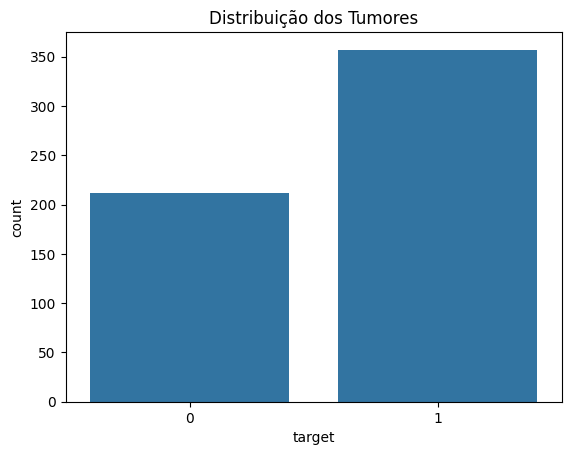

In [ ]:
sns.countplot(x=df["target"])
plt.title("Distribuição dos Tumores")
plt.show()

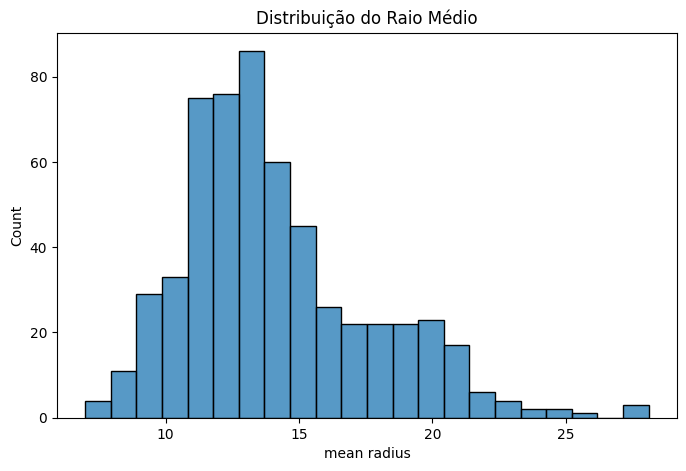

In [ ]:
plt.figure(figsize=(8,5))
sns.histplot(df["mean radius"])
plt.title("Distribuição do Raio Médio")
plt.show()

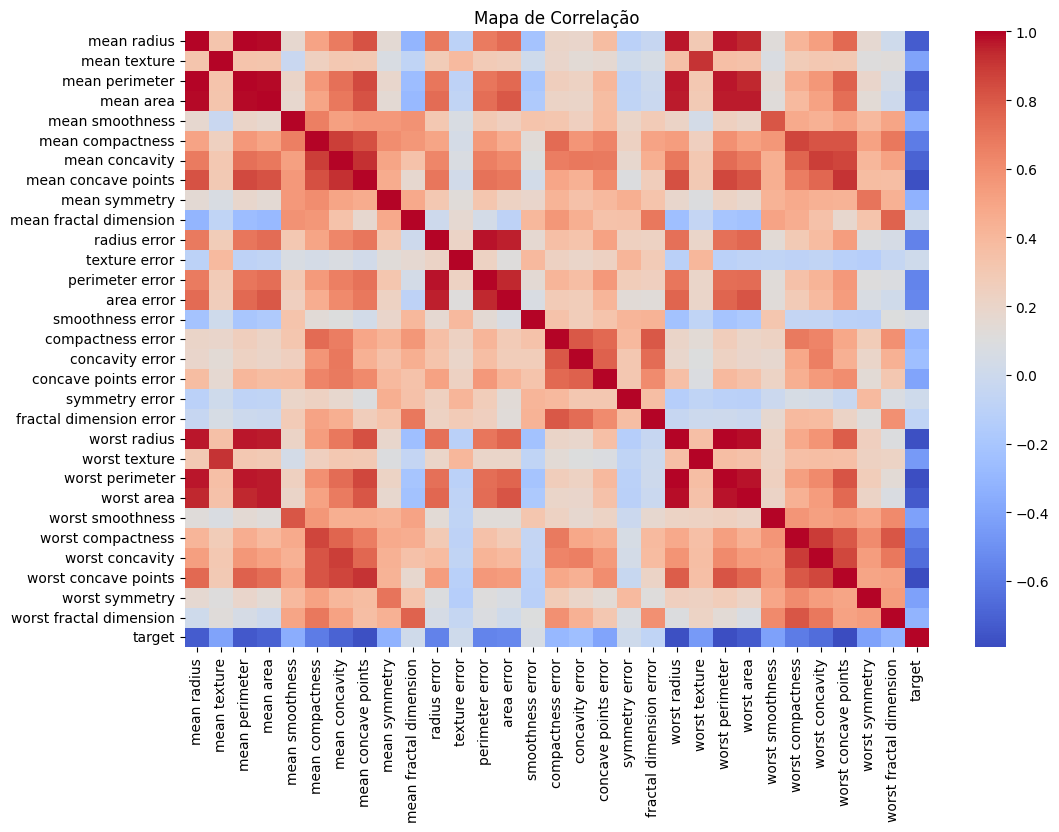

In [ ]:
plt.figure(figsize=(12,8))
sns.heatmap(df.corr(), cmap="coolwarm")
plt.title("Mapa de Correlação")
plt.show()

## Preparação dos Dados

Os dados serão separados entre atributos de entrada e variável alvo.

In [ ]:
X = df.drop("target", axis=1)
y = df["target"]

## Divisão dos Dados

Os dados foram divididos em conjuntos de treinamento e teste.

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42
)

## Treinamento do Modelo

In [ ]:
modelo = DecisionTreeClassifier(
    max_depth=4,
    random_state=42
)

modelo.fit(X_train, y_train)

DecisionTreeClassifier(max_depth=4, random_state=42)

## Visualização da Árvore Gerada

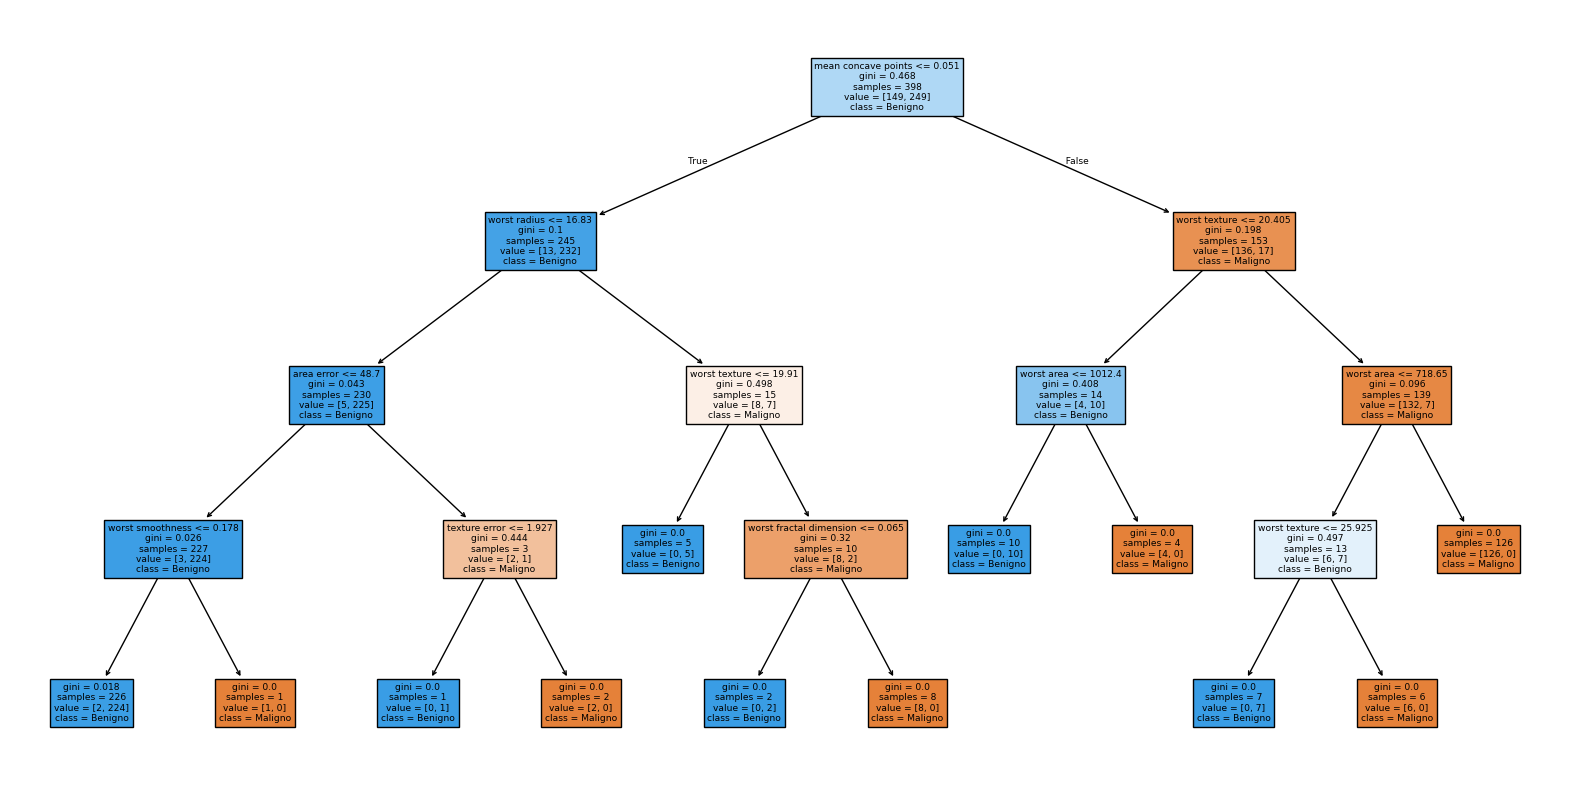

In [ ]:
plt.figure(figsize=(20,10))

tree.plot_tree(
    modelo,
    feature_names=X.columns,
    class_names=["Maligno", "Benigno"],
    filled=True
)

plt.show()

## Avaliação do Modelo



In [ ]:
y_pred = modelo.predict(X_test)

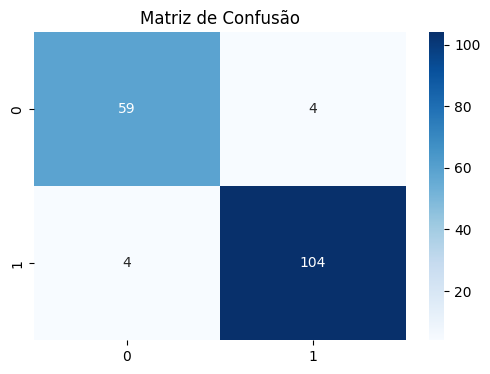

In [ ]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6,4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.title("Matriz de Confusão")
plt.show()

In [ ]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.94      0.94      0.94        63
           1       0.96      0.96      0.96       108

    accuracy                           0.95       171
   macro avg       0.95      0.95      0.95       171
weighted avg       0.95      0.95      0.95       171



## Conclusão

O algoritmo Árvore de Decisão foi capaz de realizar a classificação de tumores mamários utilizando características extraídas de exames clínicos.

Os resultados obtidos demonstram que técnicas de Machine Learning podem auxiliar na identificação de padrões relevantes para apoio ao diagnóstico médico.

Além disso, a Árvore de Decisão apresenta a vantagem de permitir interpretação visual das regras de classificação utilizadas pelo modelo.